<a href="https://colab.research.google.com/github/SanskritiVij/tp53-mutation-analysis/blob/main/TP53_survival_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install lifelines -q


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

mut = pd.read_csv("data_mutations.txt", sep="\t", comment="#", low_memory=False,
                  usecols=["Hugo_Symbol", "Variant_Classification", "Tumor_Sample_Barcode"])
clin = pd.read_csv("data_clinical_patient.txt", sep="\t", comment="#")
print(mut.shape, clin.shape)

(126252, 3) (1084, 38)


In [7]:
mut["PATIENT_ID"] = mut["Tumor_Sample_Barcode"].str[:12]
tp53 = mut[(mut["Hugo_Symbol"] == "TP53") & (mut["Variant_Classification"] != "Silent")]
tp53_patients = set(tp53["PATIENT_ID"])

clin["OS_MONTHS"] = pd.to_numeric(clin["OS_MONTHS"], errors="coerce")
clin = clin.dropna(subset=["OS_STATUS", "OS_MONTHS"]).copy()
clin = clin[clin["PATIENT_ID"].isin(mut["PATIENT_ID"])].copy()
clin["event"] = clin["OS_STATUS"].str.startswith("1").astype(int)
clin["TP53_mutant"] = clin["PATIENT_ID"].isin(tp53_patients)

print(clin["TP53_mutant"].value_counts())
print("Deaths:", clin["event"].sum())

TP53_mutant
False    661
True     348
Name: count, dtype: int64
Deaths: 136


log-rank p-value: 0.48332180023134474


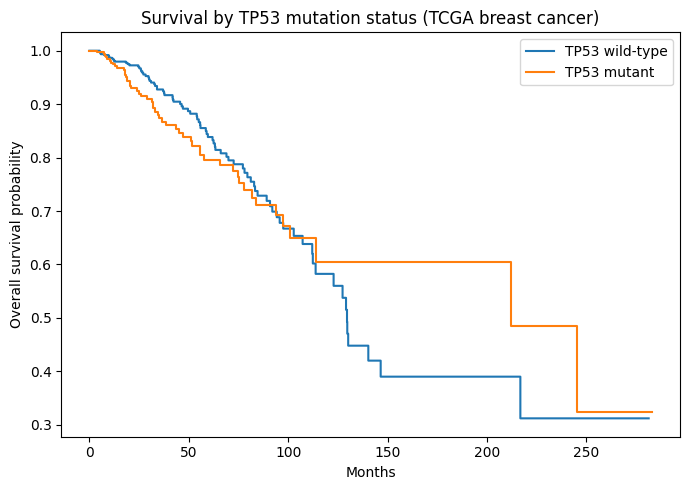

In [8]:
kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(7, 5))

for flag, grp in clin.groupby("TP53_mutant"):
    name = "TP53 mutant" if flag else "TP53 wild-type"
    kmf.fit(grp["OS_MONTHS"], grp["event"], label=name)
    kmf.plot_survival_function(ax=ax, ci_show=False)

m = clin[clin["TP53_mutant"]]
w = clin[~clin["TP53_mutant"]]
res = logrank_test(m["OS_MONTHS"], w["OS_MONTHS"], m["event"], w["event"])
print("log-rank p-value:", res.p_value)

ax.set_xlabel("Months")
ax.set_ylabel("Overall survival probability")
ax.set_title("Survival by TP53 mutation status (TCGA breast cancer)")
plt.tight_layout()
plt.savefig("tp53_survival.png", dpi=200)
plt.show()

I compared overall survival between patients with a TP53 mutation (348) and without one (661) using Kaplan-Meier curves and a log-rank test. There were 136 deaths in total. The log-rank p-value was 0.48, so there was no significant difference in survival between the groups. The mutant curve sits slightly below the wild-type curve for the first 80 months or so, and the two cross at around 100 months. After about 120 months the curves separate again, but few patients are followed that long, so that part rests on a handful of events. This analysis does not adjust for subtype, stage, or age.